# Clasificación de imágenes CIFAR-10: CNN, transfer learning y fine-tuning

El objetivo es comparar tres modelos de redes convolucionales para clasificar las imágenes de CIFAR-10 en 10 categorías: una CNN entrenada desde cero, un modelo con transfer learning sobre MobileNetV2 y el mismo modelo con fine-tuning. Después se aplica GradCAM para ver en qué zonas de las imágenes se fija el mejor modelo al predecir.

**Librerías**

In [3]:
import numpy as np
from tensorflow import keras
import matplotlib.pyplot as plt
from tensorflow.keras.datasets import cifar10
from sklearn.model_selection import train_test_split
from tensorflow.keras import layers, Sequential, models
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras import Model
from tensorflow.keras.callbacks import EarlyStopping
import tensorflow as tf

**Análisis y preprocesamiento de datos**

Carga de los datos:

In [4]:
(X_train_full, y_train_full), (X_test, y_test) = cifar10.load_data()

print(f"Entrenamiento: {X_train_full.shape}")
print(f"Test:          {X_test.shape}")
print(f"Rango píxeles: {X_train_full.min()} - {X_train_full.max()}")

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 16s 0us/step
Entrenamiento: (50000, 32, 32, 3)
Test:          (10000, 32, 32, 3)
Rango píxeles: 0 - 255


In [5]:
# Nombres de las clases
class_names = ['airplane', 'automobile', 'bird', 'cat', 'deer',
               'dog', 'frog', 'horse', 'ship', 'truck']

Visualización de ejemplos:

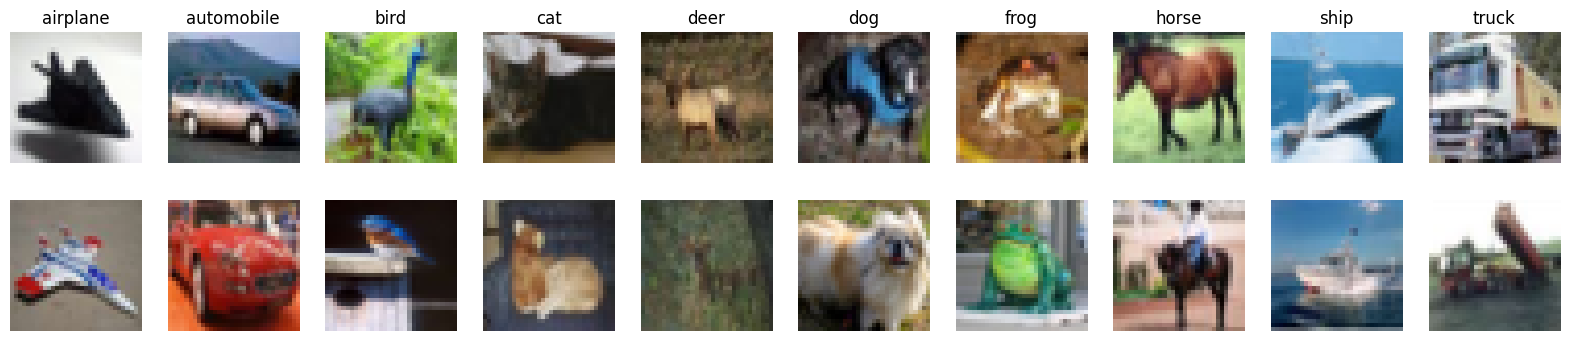

In [6]:
fig, axes = plt.subplots(2, 10, figsize=(20, 4))
for class_idx in range(10):
    indices = np.where(y_train_full.flatten() == class_idx)[0]
    for row in range(2):
        img = X_train_full[indices[row]]
        axes[row, class_idx].imshow(img)
        axes[row, class_idx].axis('off')
        if row == 0:
            axes[row, class_idx].set_title(class_names[class_idx], fontsize=12)
plt.show()

Balance de clases:

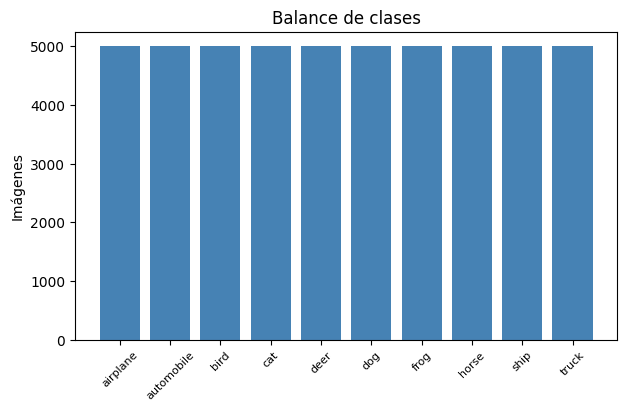

In [7]:
unique, counts = np.unique(y_train_full, return_counts=True)

plt.figure(figsize=(7, 4))
plt.bar(class_names, counts, color='steelblue')
plt.title('Balance de clases')
plt.ylabel('Imágenes')
plt.xticks(rotation=45, fontsize=8)
plt.show()

División en entrenamiento, validación y prueba:

In [8]:
# Separamos 10% para validación
X_train, X_val, y_train, y_val = train_test_split(
    X_train_full, y_train_full,
    test_size=0.1,
    random_state=42,
    stratify=y_train_full  # para mantener el balance de clases
)

print(f"Train: {X_train.shape}")
print(f"Val:   {X_val.shape}")
print(f"Test:  {X_test.shape}")

Train: (45000, 32, 32, 3)
Val:   (5000, 32, 32, 3)
Test:  (10000, 32, 32, 3)


Normalización:

In [9]:
# Escalamos píxeles al rango [0, 1]
X_train = X_train.astype('float32') / 255.0
X_val   = X_val.astype('float32') / 255.0
X_test  = X_test.astype('float32') / 255.0

print(f"Rango tras normalización: {X_train.min()} - {X_train.max()}")

Rango tras normalización: 0.0 - 1.0


Data augmentation:

Se aplican transformaciones aleatorias sobre el conjunto de entrenamiento
para aumentar la diversidad de los datos y mejorar la generalización del modelo.

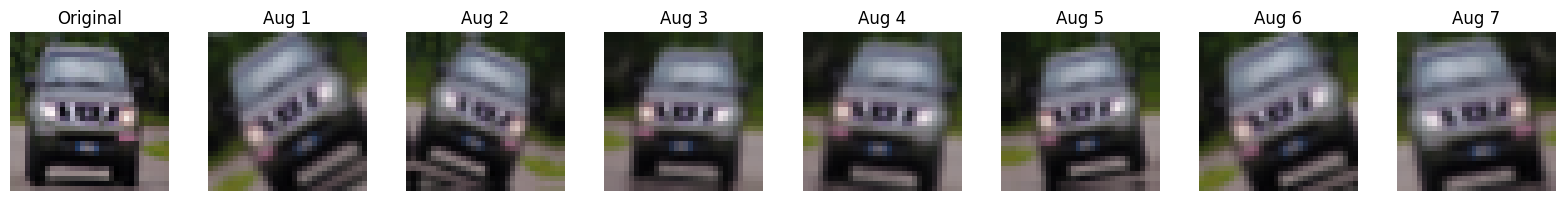

In [10]:
# Solo se aplica durante el entrenamiento
data_augmentation = Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1),
], name="data_augmentation")

# Visualizamos el efecto del augmentation
sample_img = X_train[:1]
fig, axes = plt.subplots(1, 8, figsize=(16, 2))
axes[0].imshow(sample_img[0])
axes[0].set_title('Original')
axes[0].axis('off')
for i in range(1, 8):
    aug_img = data_augmentation(sample_img, training=True)
    axes[i].imshow(aug_img[0].numpy())
    axes[i].set_title(f'Aug {i}')
    axes[i].axis('off')
plt.tight_layout()
plt.savefig('data_augmentation.png', dpi=150)
plt.show()

**1. Modelos**

**1.1. Modelo 1: CNN línea base**

In [11]:
model1 = models.Sequential([
    layers.Input(shape=(32, 32, 3)),

    # Augmentation
    data_augmentation,

    # Bloque 1
    layers.Conv2D(32, (3,3), activation='relu', padding='same'),
    layers.BatchNormalization(),
    layers.MaxPooling2D(2,2),
    layers.Dropout(0.25),

    # Bloque 2
    layers.Conv2D(64, (3,3), activation='relu', padding='same'),
    layers.BatchNormalization(),
    layers.MaxPooling2D(2,2),
    layers.Dropout(0.25),

    # Bloque 3
    layers.Conv2D(128, (3,3), activation='relu', padding='same'),
    layers.BatchNormalization(),
    layers.MaxPooling2D(2,2),
    layers.Dropout(0.25),

    # Clasificador
    layers.Flatten(),
    layers.Dense(256, activation='relu'),
    layers.Dropout(0.5),
    layers.Dense(10, activation='softmax')
], name="modelo1_baseline")

model1.summary()

Model: "modelo1_baseline"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ data_augmentation (Sequential)  │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 8, 8, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 8, 8, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       524,544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         2,570 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 621,258 (2.37 MB)

 Trainable params: 620,810 (2.37 MB)

 Non-trainable params: 448 (1.75 KB)

Entrenamiento:

In [12]:
model1.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

history1 = model1.fit(
    X_train, y_train,
    epochs=50,
    batch_size=64,
    validation_data=(X_val, y_val),
    verbose=1
)

Epoch 1/50
704/704 ━━━━━━━━━━━━━━━━━━━━ 18s 16ms/step - accuracy: 0.3335 - loss: 1.8468 - val_accuracy: 0.3470 - val_loss: 2.1613
Epoch 2/50
704/704 ━━━━━━━━━━━━━━━━━━━━ 10s 14ms/step - accuracy: 0.4222 - loss: 1.5926 - val_accuracy: 0.4676 - val_loss: 1.5530
Epoch 3/50
704/704 ━━━━━━━━━━━━━━━━━━━━ 9s 13ms/step - accuracy: 0.4671 - loss: 1.4788 - val_accuracy: 0.5536 - val_loss: 1.2424
Epoch 4/50
704/704 ━━━━━━━━━━━━━━━━━━━━ 8s 12ms/step - accuracy: 0.4969 - loss: 1.4048 - val_accuracy: 0.4242 - val_loss: 1.9286
Epoch 5/50
704/704 ━━━━━━━━━━━━━━━━━━━━ 9s 13ms/step - accuracy: 0.5221 - loss: 1.3382 - val_accuracy: 0.5976 - val_loss: 1.1380
Epoch 6/50
704/704 ━━━━━━━━━━━━━━━━━━━━ 9s 13ms/step - accuracy: 0.5414 - loss: 1.2983 - val_accuracy: 0.5942 - val_loss: 1.1563
Epoch 7/50
704/704 ━━━━━━━━━━━━━━━━━━━━ 9s 13ms/step - accuracy: 0.5545 - loss: 1.2612 - val_accuracy: 0.5572 - val_loss: 1.2996
Epoch 8/50
704/704 ━━━━━━━━━━━━━━━━━━━━ 9s 12ms/step - accuracy: 0.5643 - loss: 1.2321 - val_ac

Curvas de aprendizaje:

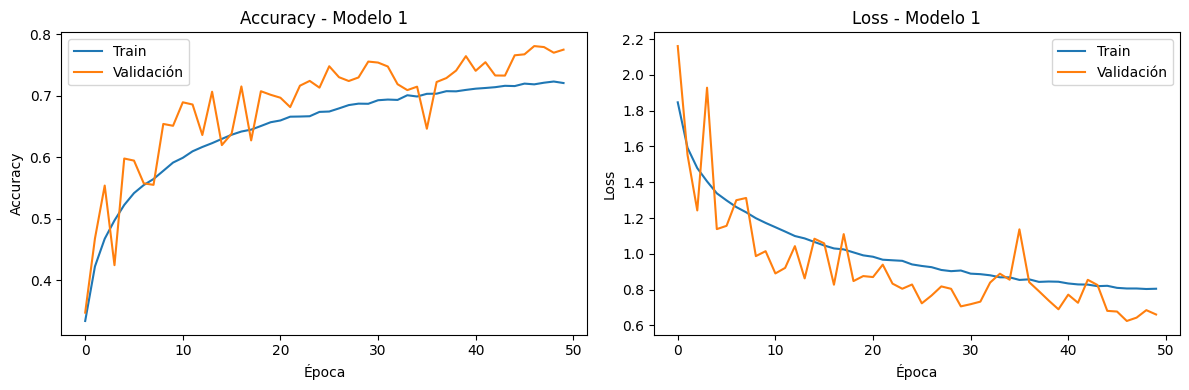

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Accuracy
axes[0].plot(history1.history['accuracy'], label='Train')
axes[0].plot(history1.history['val_accuracy'], label='Validación')
axes[0].set_title('Accuracy - Modelo 1')
axes[0].set_xlabel('Época')
axes[0].set_ylabel('Accuracy')
axes[0].legend()

# Loss
axes[1].plot(history1.history['loss'], label='Train')
axes[1].plot(history1.history['val_loss'], label='Validación')
axes[1].set_title('Loss - Modelo 1')
axes[1].set_xlabel('Época')
axes[1].set_ylabel('Loss')
axes[1].legend()

plt.tight_layout()
plt.savefig('curvas_modelo1.png', dpi=150)
plt.show()

Métricas sobre test:

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step
              precision    recall  f1-score   support

    airplane       0.86      0.74      0.80      1000
  automobile       0.88      0.90      0.89      1000
        bird       0.84      0.57      0.68      1000
         cat       0.63      0.57      0.59      1000
        deer       0.74      0.75      0.74      1000
         dog       0.69      0.69      0.69      1000
        frog       0.64      0.94      0.76      1000
       horse       0.85      0.81      0.83      1000
        ship       0.90      0.85      0.87      1000
       truck       0.78      0.88      0.83      1000

    accuracy                           0.77     10000
   macro avg       0.78      0.77      0.77     10000
weighted avg       0.78      0.77      0.77     10000



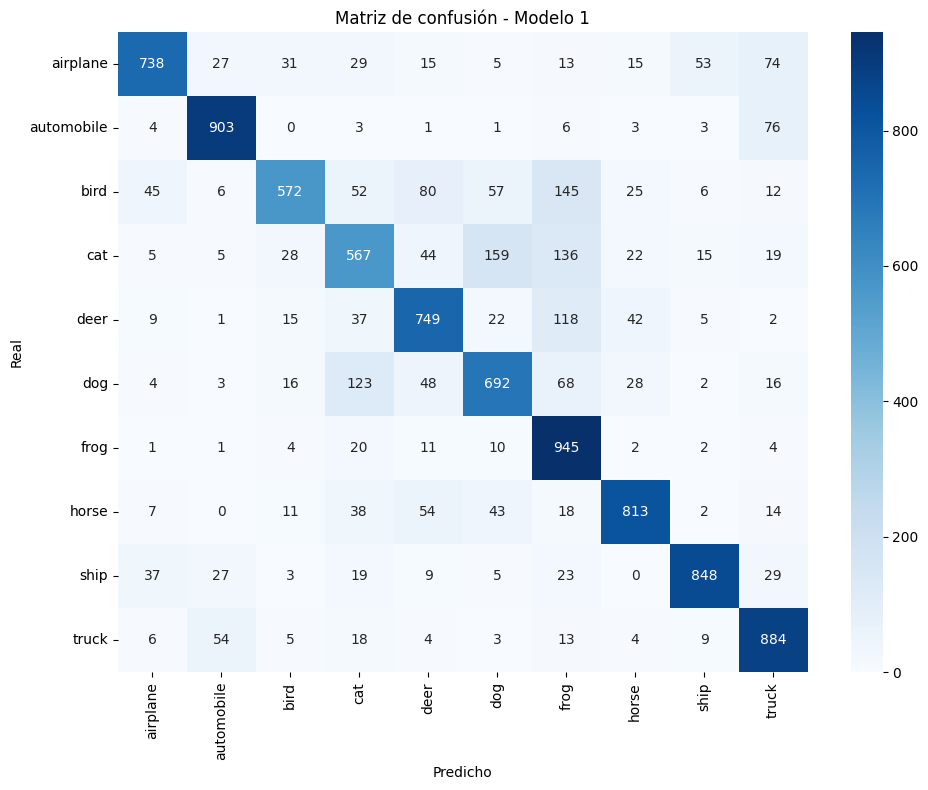

In [14]:
# Predicciones
y_pred1 = model1.predict(X_test).argmax(axis=1)

# Classification report
print(classification_report(y_test, y_pred1, target_names=class_names))

# Matriz de confusión
cm = confusion_matrix(y_test, y_pred1)
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', xticklabels=class_names,
            yticklabels=class_names, cmap='Blues')
plt.title('Matriz de confusión - Modelo 1')
plt.ylabel('Real')
plt.xlabel('Predicho')
plt.tight_layout()
plt.savefig('confusion_modelo1.png', dpi=150)
plt.show()

**1.2. Modelo 2: Transfer Learning**

In [15]:
base_model = MobileNetV2(
    weights='imagenet',
    include_top=False,
    input_shape=(96, 96, 3)
)

base_model.trainable = False

inputs = layers.Input(shape=(32, 32, 3))
x = data_augmentation(inputs, training=True)
x = layers.Resizing(96, 96)(x)
x = layers.Rescaling(1./127.5, offset=-1)(x)
x = base_model(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(10, activation='softmax')(x)

model2 = Model(inputs, outputs, name="modelo2_transfer_learning")
model2.summary()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step


Model: "modelo2_transfer_learning"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_3 (InputLayer)      │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resizing (Resizing)             │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_96             │ (None, 3, 3, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │        12,810 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,270,794 (8.66 MB)

 Trainable params: 12,810 (50.04 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

Entrenamiento:

In [16]:
# Datos en rango [0, 255] para MobileNetV2
(X_train_full, y_train_full), (X_test, y_test) = cifar10.load_data()

X_train_raw, X_val_raw, y_train_raw, y_val_raw = train_test_split(
    X_train_full.astype('float32'),
    y_train_full,
    test_size=0.1,
    random_state=42,
    stratify=y_train_full
)
X_test_raw = X_test.astype('float32')

print(f"Train raw: {X_train_raw.shape}, rango: {X_train_raw.min()} - {X_train_raw.max()}")
print(f"Val raw:   {X_val_raw.shape}")
print(f"Test raw:  {X_test_raw.shape}")

Train raw: (45000, 32, 32, 3), rango: 0.0 - 255.0
Val raw:   (5000, 32, 32, 3)
Test raw:  (10000, 32, 32, 3)


In [17]:
model2.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

early_stop2 = EarlyStopping(
    monitor='val_loss',
    patience=10,
    restore_best_weights=True
)

history2 = model2.fit(
    X_train_raw, y_train_raw,
    epochs=50,
    batch_size=64,
    validation_data=(X_val_raw, y_val_raw),
    callbacks=[early_stop2],
    verbose=1
)

Epoch 1/50
704/704 ━━━━━━━━━━━━━━━━━━━━ 26s 30ms/step - accuracy: 0.5856 - loss: 1.2293 - val_accuracy: 0.7944 - val_loss: 0.6291
Epoch 2/50
704/704 ━━━━━━━━━━━━━━━━━━━━ 20s 28ms/step - accuracy: 0.6629 - loss: 0.9742 - val_accuracy: 0.8246 - val_loss: 0.5324
Epoch 3/50
704/704 ━━━━━━━━━━━━━━━━━━━━ 19s 27ms/step - accuracy: 0.6696 - loss: 0.9417 - val_accuracy: 0.8238 - val_loss: 0.5285
Epoch 4/50
704/704 ━━━━━━━━━━━━━━━━━━━━ 19s 27ms/step - accuracy: 0.6755 - loss: 0.9330 - val_accuracy: 0.8060 - val_loss: 0.5790
Epoch 5/50
704/704 ━━━━━━━━━━━━━━━━━━━━ 19s 27ms/step - accuracy: 0.6768 - loss: 0.9292 - val_accuracy: 0.8206 - val_loss: 0.5463
Epoch 6/50
704/704 ━━━━━━━━━━━━━━━━━━━━ 21s 27ms/step - accuracy: 0.6768 - loss: 0.9300 - val_accuracy: 0.8126 - val_loss: 0.5590
Epoch 7/50
704/704 ━━━━━━━━━━━━━━━━━━━━ 19s 27ms/step - accuracy: 0.6775 - loss: 0.9267 - val_accuracy: 0.8132 - val_loss: 0.5597
Epoch 8/50
704/704 ━━━━━━━━━━━━━━━━━━━━ 19s 27ms/step - accuracy: 0.6817 - loss: 0.9290 - 

Curvas de aprendizaje:

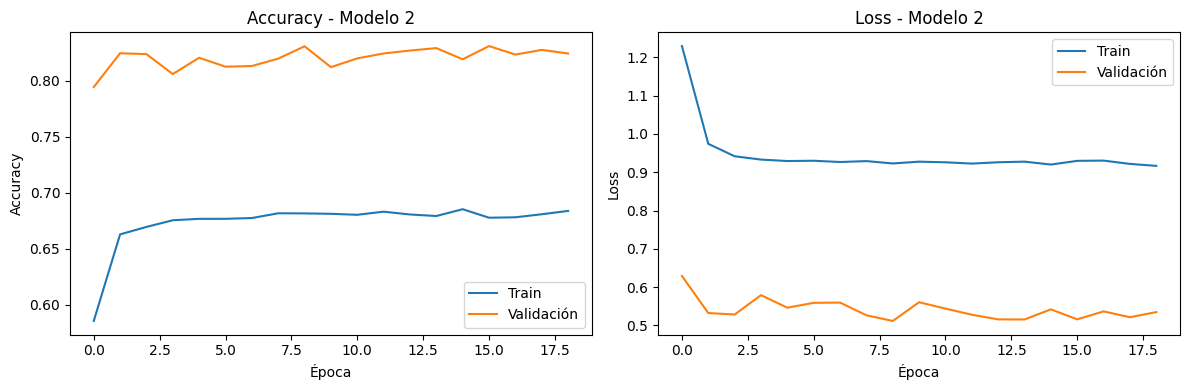

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(history2.history['accuracy'], label='Train')
axes[0].plot(history2.history['val_accuracy'], label='Validación')
axes[0].set_title('Accuracy - Modelo 2')
axes[0].set_xlabel('Época')
axes[0].set_ylabel('Accuracy')
axes[0].legend()

axes[1].plot(history2.history['loss'], label='Train')
axes[1].plot(history2.history['val_loss'], label='Validación')
axes[1].set_title('Loss - Modelo 2')
axes[1].set_xlabel('Época')
axes[1].set_ylabel('Loss')
axes[1].legend()

plt.tight_layout()
plt.savefig('curvas_modelo2.png', dpi=150)
plt.show()

Métricas sobre test:

313/313 ━━━━━━━━━━━━━━━━━━━━ 7s 17ms/step
              precision    recall  f1-score   support

    airplane       0.85      0.83      0.84      1000
  automobile       0.86      0.94      0.90      1000
        bird       0.87      0.70      0.78      1000
         cat       0.70      0.67      0.69      1000
        deer       0.82      0.78      0.80      1000
         dog       0.78      0.76      0.77      1000
        frog       0.85      0.87      0.86      1000
       horse       0.78      0.89      0.83      1000
        ship       0.91      0.86      0.88      1000
       truck       0.82      0.93      0.87      1000

    accuracy                           0.82     10000
   macro avg       0.82      0.82      0.82     10000
weighted avg       0.82      0.82      0.82     10000



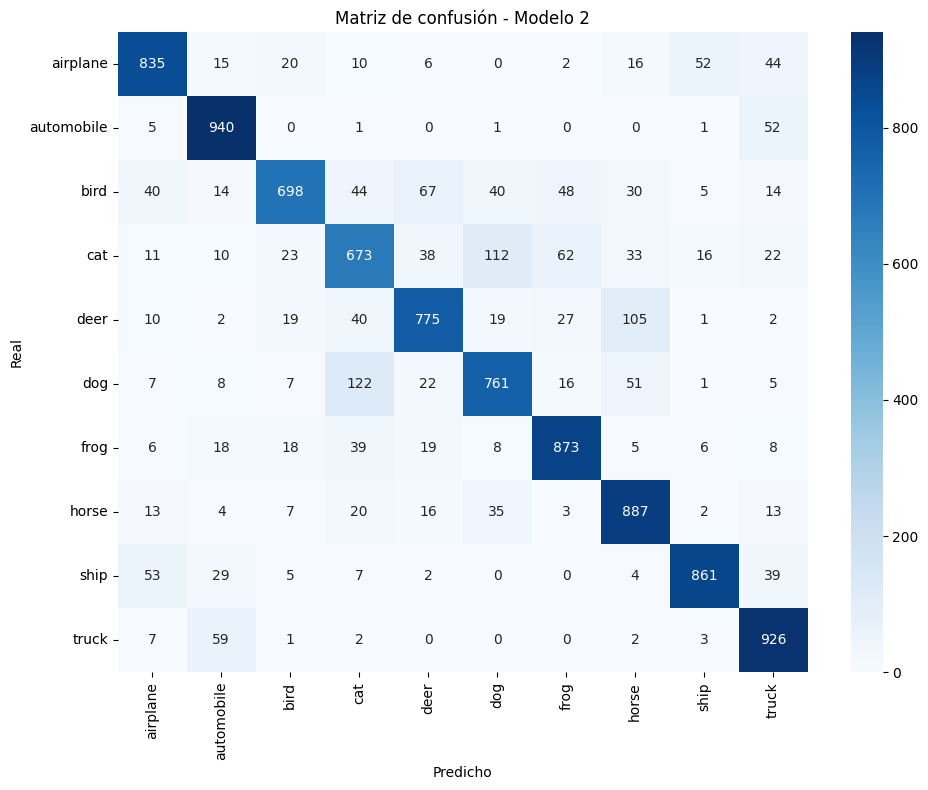

In [19]:
y_pred2 = model2.predict(X_test_raw).argmax(axis=1)
print(classification_report(y_test.flatten(), y_pred2, target_names=class_names))

# Matriz de confusión
cm2 = confusion_matrix(y_test.flatten(), y_pred2)
plt.figure(figsize=(10, 8))
sns.heatmap(cm2, annot=True, fmt='d', xticklabels=class_names,
            yticklabels=class_names, cmap='Blues')
plt.title('Matriz de confusión - Modelo 2')
plt.ylabel('Real')
plt.xlabel('Predicho')
plt.tight_layout()
plt.show()

**1.3. Modelo 3: Fine-Tuning**

In [20]:
# Partimos del modelo2 ya entrenado
# Descongelamos las últimas 30 capas de MobileNetV2
base_model.trainable = True

# Congelamos todas las capas menos las últimas 30
for layer in base_model.layers[:-30]:
    layer.trainable = False

print(f"Capas entrenables ahora: {len([l for l in base_model.layers if l.trainable])}")

model3 = model2

model3.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-5),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

early_stop3 = EarlyStopping(
    monitor='val_loss',
    patience=10,
    restore_best_weights=True
)

history3 = model3.fit(
    X_train_raw, y_train_raw,
    epochs=30,
    batch_size=64,
    validation_data=(X_val_raw, y_val_raw),
    callbacks=[early_stop3],
    verbose=1
)

Capas entrenables ahora: 30
Epoch 1/30
704/704 ━━━━━━━━━━━━━━━━━━━━ 42s 46ms/step - accuracy: 0.6081 - loss: 1.3888 - val_accuracy: 0.8110 - val_loss: 0.6037
Epoch 2/30
704/704 ━━━━━━━━━━━━━━━━━━━━ 31s 44ms/step - accuracy: 0.6621 - loss: 1.1280 - val_accuracy: 0.8254 - val_loss: 0.5656
Epoch 3/30
704/704 ━━━━━━━━━━━━━━━━━━━━ 30s 43ms/step - accuracy: 0.6877 - loss: 1.0129 - val_accuracy: 0.8326 - val_loss: 0.5444
Epoch 4/30
704/704 ━━━━━━━━━━━━━━━━━━━━ 31s 44ms/step - accuracy: 0.7022 - loss: 0.9350 - val_accuracy: 0.8352 - val_loss: 0.5243
Epoch 5/30
704/704 ━━━━━━━━━━━━━━━━━━━━ 31s 43ms/step - accuracy: 0.7165 - loss: 0.8615 - val_accuracy: 0.8390 - val_loss: 0.4995
Epoch 6/30
704/704 ━━━━━━━━━━━━━━━━━━━━ 31s 44ms/step - accuracy: 0.7284 - loss: 0.8159 - val_accuracy: 0.8452 - val_loss: 0.4796
Epoch 7/30
704/704 ━━━━━━━━━━━━━━━━━━━━ 31s 43ms/step - accuracy: 0.7378 - loss: 0.7826 - val_accuracy: 0.8508 - val_loss: 0.4557
Epoch 8/30
704/704 ━━━━━━━━━━━━━━━━━━━━ 31s 44ms/step - accura

Curvas de aprendizaje:

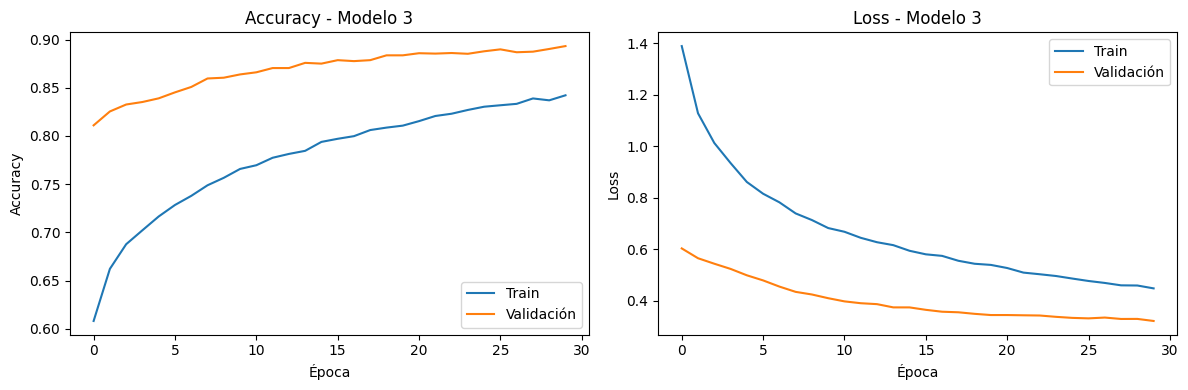

In [21]:

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(history3.history['accuracy'], label='Train')
axes[0].plot(history3.history['val_accuracy'], label='Validación')
axes[0].set_title('Accuracy - Modelo 3')
axes[0].set_xlabel('Época')
axes[0].set_ylabel('Accuracy')
axes[0].legend()

axes[1].plot(history3.history['loss'], label='Train')
axes[1].plot(history3.history['val_loss'], label='Validación')
axes[1].set_title('Loss - Modelo 3')
axes[1].set_xlabel('Época')
axes[1].set_ylabel('Loss')
axes[1].legend()

plt.tight_layout()
plt.savefig('curvas_modelo3.png', dpi=150)
plt.show()

Métricas sobre test:

313/313 ━━━━━━━━━━━━━━━━━━━━ 6s 17ms/step
              precision    recall  f1-score   support

    airplane       0.90      0.90      0.90      1000
  automobile       0.93      0.96      0.94      1000
        bird       0.90      0.85      0.88      1000
         cat       0.82      0.76      0.79      1000
        deer       0.88      0.86      0.87      1000
         dog       0.85      0.81      0.83      1000
        frog       0.86      0.94      0.90      1000
       horse       0.89      0.92      0.90      1000
        ship       0.93      0.93      0.93      1000
       truck       0.92      0.94      0.93      1000

    accuracy                           0.89     10000
   macro avg       0.89      0.89      0.89     10000
weighted avg       0.89      0.89      0.89     10000



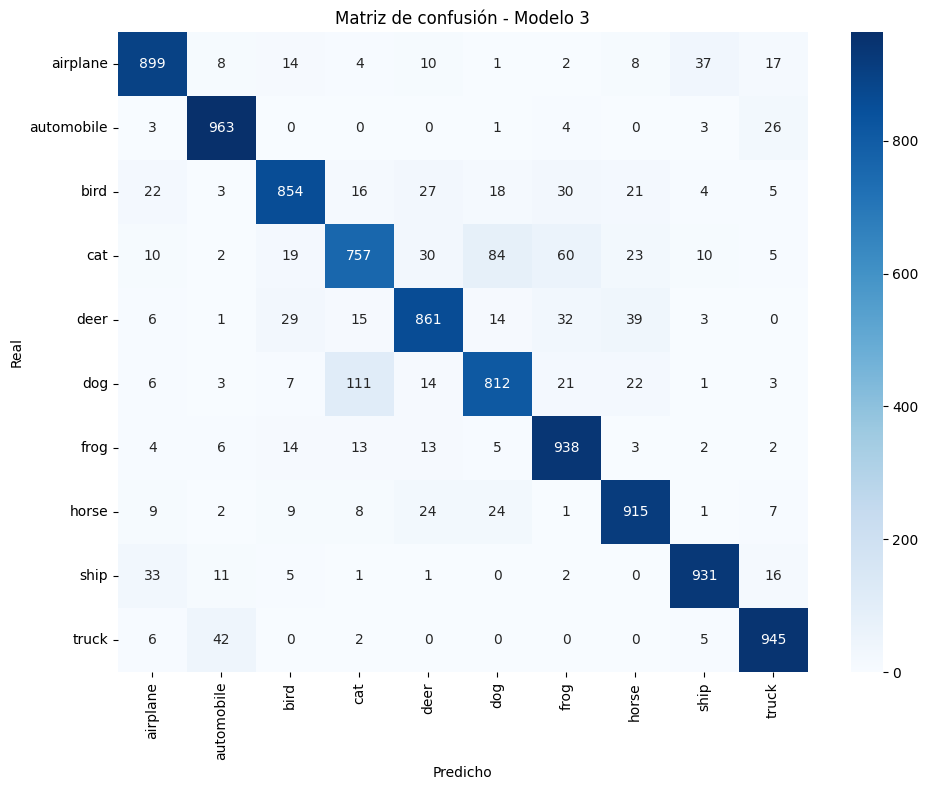

In [22]:
y_pred3 = model3.predict(X_test_raw).argmax(axis=1)
print(classification_report(y_test.flatten(), y_pred3, target_names=class_names))

# Matriz de confusión
cm3 = confusion_matrix(y_test.flatten(), y_pred3)
plt.figure(figsize=(10, 8))
sns.heatmap(cm3, annot=True, fmt='d', xticklabels=class_names,
            yticklabels=class_names, cmap='Blues')
plt.title('Matriz de confusión - Modelo 3')
plt.ylabel('Real')
plt.xlabel('Predicho')
plt.tight_layout()
plt.show()

**2. Explicabilidad con GradCAM**

In [28]:
resizing = model3.get_layer('resizing')
rescaling = model3.get_layer('rescaling')
mobilenet = model3.get_layer('mobilenetv2_1.00_96')
gap = model3.get_layer('global_average_pooling2d')
dropout = model3.get_layer('dropout_4')
dense = model3.get_layer('dense_2')

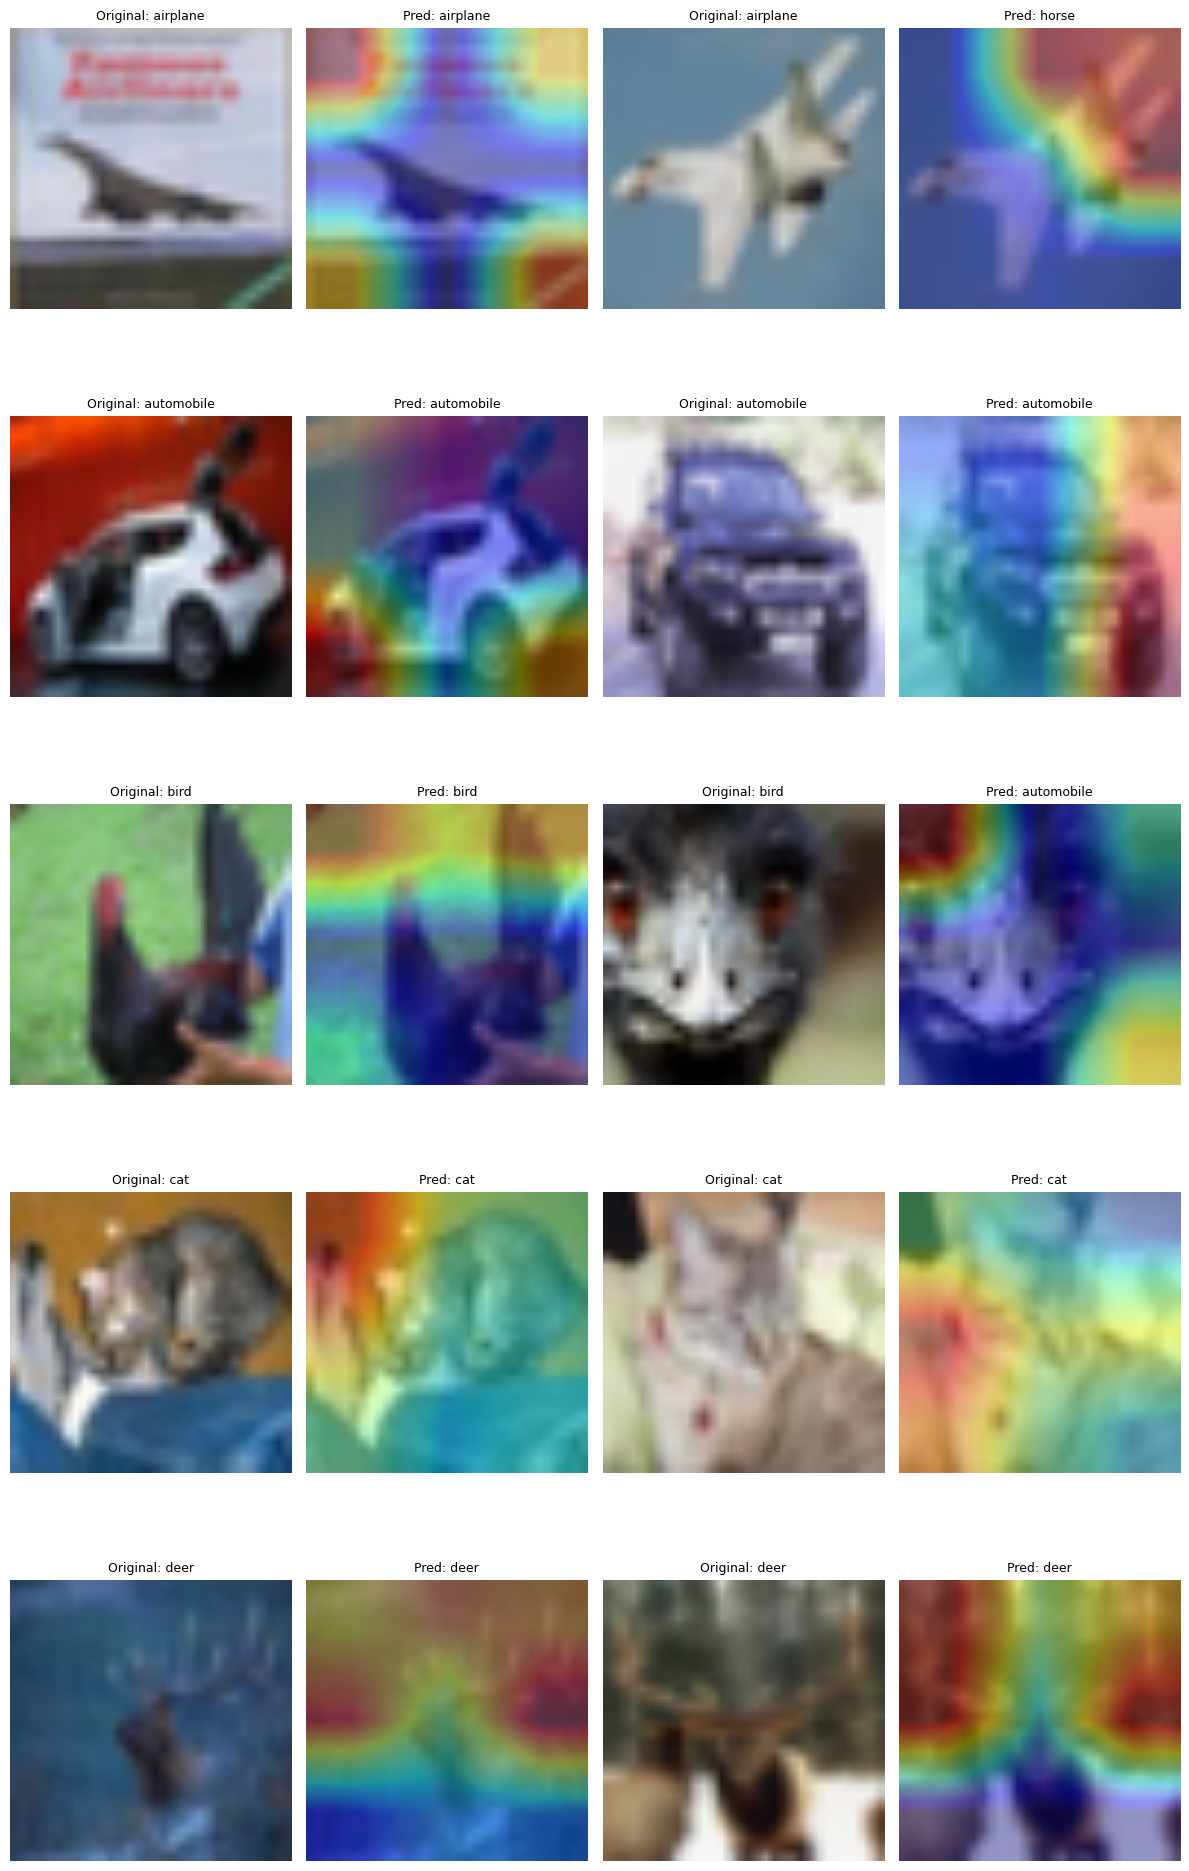

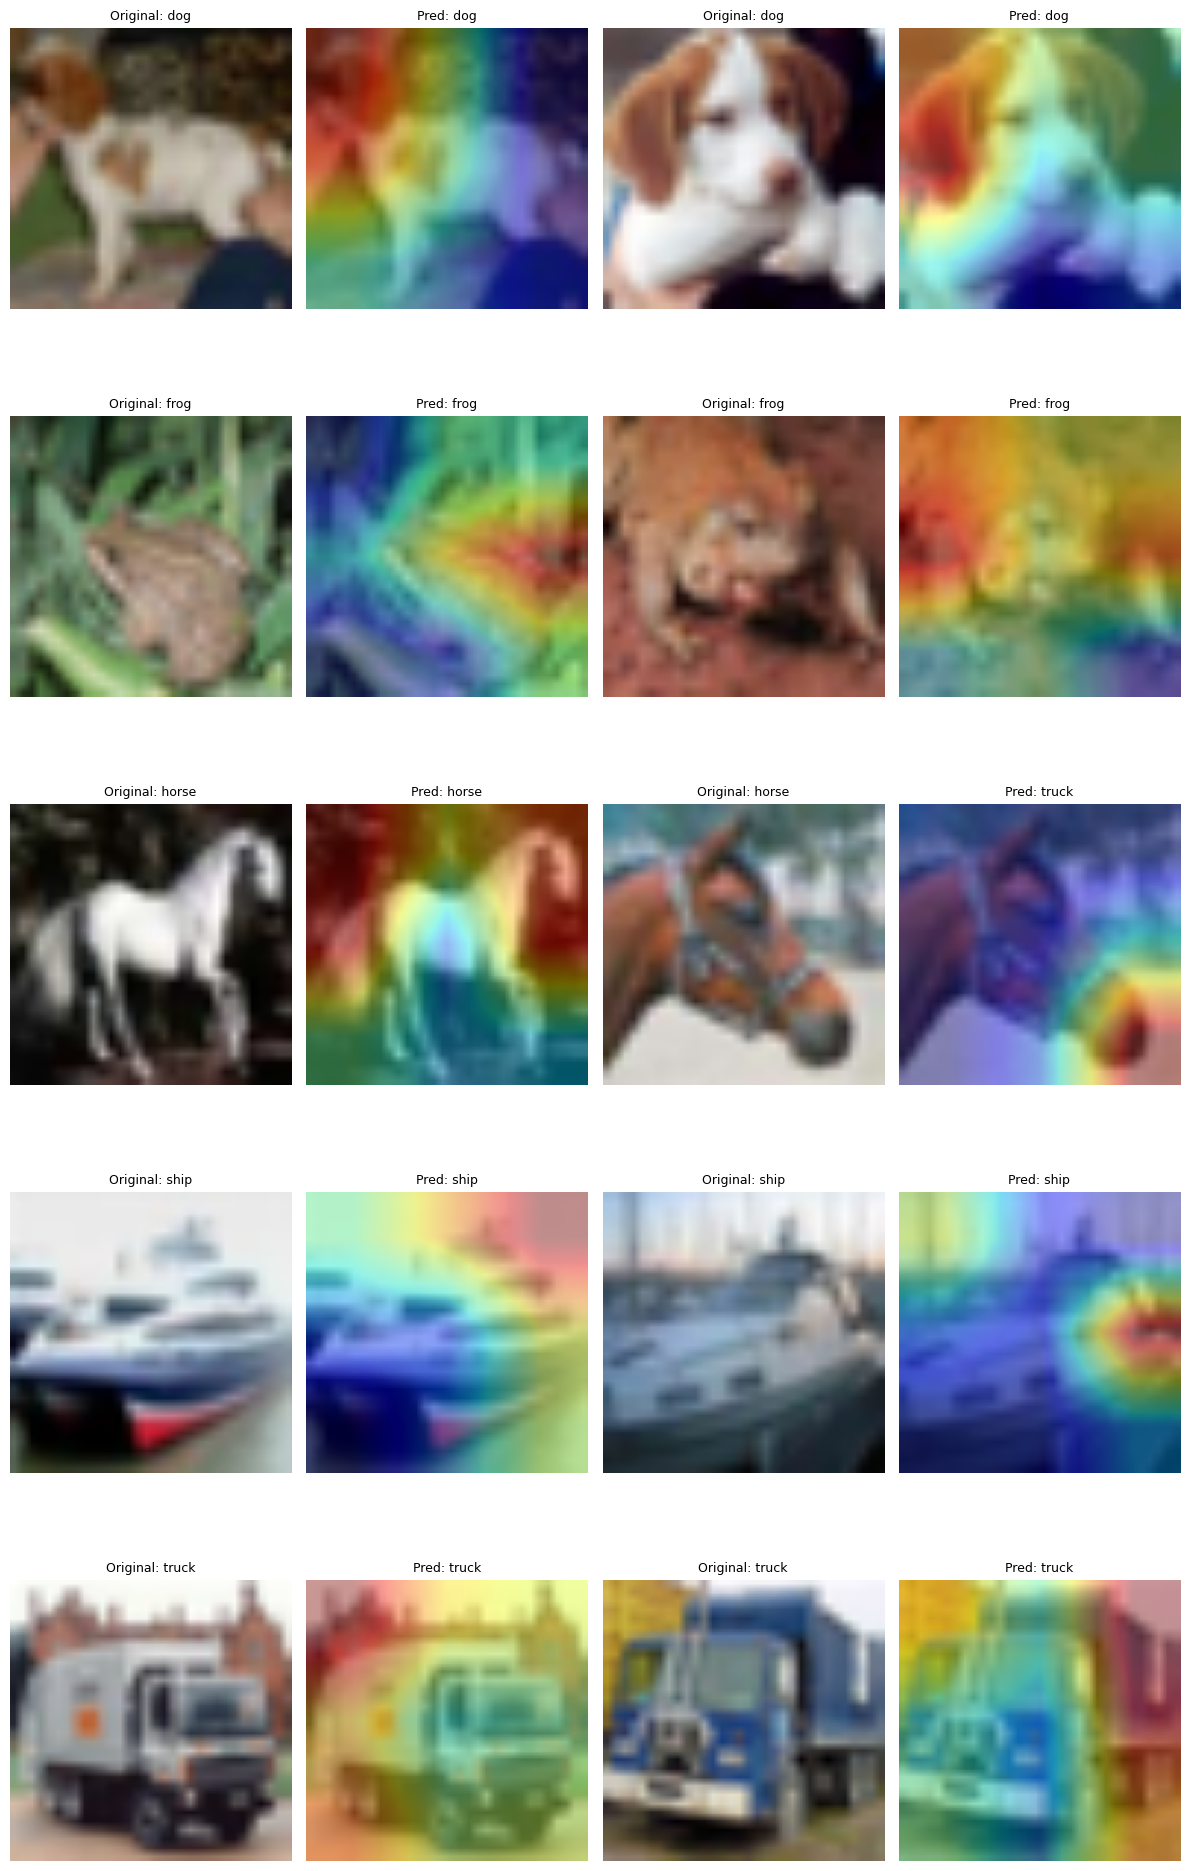

In [29]:
# primeras 5 clases
fig, axes = plt.subplots(5, 4, figsize=(12, 20))

for class_idx in range(5):
    indices = np.where(y_test.flatten() == class_idx)[0]

    for col, img_idx in enumerate(indices[:2]):
        img = X_test_raw[img_idx]
        img_array = np.expand_dims(img, axis=0)

        x = resizing(img_array)
        x = rescaling(x)

        with tf.GradientTape() as tape:
            tape.watch(x)
            mobilenet_out = mobilenet(x, training=False)
            gap_out = gap(mobilenet_out)
            drop_out = dropout(gap_out, training=False)
            preds = dense(drop_out)
            pred_index = tf.argmax(preds[0])
            class_channel = preds[:, pred_index]

        grads = tape.gradient(class_channel, mobilenet_out)
        pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))
        heatmap = mobilenet_out[0] @ pooled_grads[..., tf.newaxis]
        heatmap = tf.squeeze(heatmap)
        heatmap = tf.maximum(heatmap, 0) / (tf.math.reduce_max(heatmap) + 1e-8)
        heatmap = heatmap.numpy()

        img_96 = tf.image.resize(img[np.newaxis], (96, 96)).numpy()[0]
        heatmap_resized = tf.image.resize(
            heatmap[..., tf.newaxis], (96, 96)
        ).numpy().squeeze()
        heatmap_colored = plt.cm.jet(heatmap_resized)[:, :, :3]
        superimposed = heatmap_colored * 0.4 + (img_96 / 255.0) * 0.6
        superimposed = np.clip(superimposed, 0, 1)

        axes[class_idx, col*2].imshow(img_96.astype('uint8'))
        axes[class_idx, col*2].set_title(f'Original: {class_names[class_idx]}', fontsize=9)
        axes[class_idx, col*2].axis('off')

        axes[class_idx, col*2+1].imshow(superimposed)
        axes[class_idx, col*2+1].set_title(f'Pred: {class_names[pred_index.numpy()]}', fontsize=9)
        axes[class_idx, col*2+1].axis('off')

plt.tight_layout()
plt.savefig('gradcam_clases_1_5.png', dpi=150, bbox_inches='tight')
plt.show()

# últimas 5 clases
fig, axes = plt.subplots(5, 4, figsize=(12, 20))

for i, class_idx in enumerate(range(5, 10)):
    indices = np.where(y_test.flatten() == class_idx)[0]

    for col, img_idx in enumerate(indices[:2]):
        img = X_test_raw[img_idx]
        img_array = np.expand_dims(img, axis=0)

        x = resizing(img_array)
        x = rescaling(x)

        with tf.GradientTape() as tape:
            tape.watch(x)
            mobilenet_out = mobilenet(x, training=False)
            gap_out = gap(mobilenet_out)
            drop_out = dropout(gap_out, training=False)
            preds = dense(drop_out)
            pred_index = tf.argmax(preds[0])
            class_channel = preds[:, pred_index]

        grads = tape.gradient(class_channel, mobilenet_out)
        pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))
        heatmap = mobilenet_out[0] @ pooled_grads[..., tf.newaxis]
        heatmap = tf.squeeze(heatmap)
        heatmap = tf.maximum(heatmap, 0) / (tf.math.reduce_max(heatmap) + 1e-8)
        heatmap = heatmap.numpy()

        img_96 = tf.image.resize(img[np.newaxis], (96, 96)).numpy()[0]
        heatmap_resized = tf.image.resize(
            heatmap[..., tf.newaxis], (96, 96)
        ).numpy().squeeze()
        heatmap_colored = plt.cm.jet(heatmap_resized)[:, :, :3]
        superimposed = heatmap_colored * 0.4 + (img_96 / 255.0) * 0.6
        superimposed = np.clip(superimposed, 0, 1)

        axes[i, col*2].imshow(img_96.astype('uint8'))
        axes[i, col*2].set_title(f'Original: {class_names[class_idx]}', fontsize=9)
        axes[i, col*2].axis('off')

        axes[i, col*2+1].imshow(superimposed)
        axes[i, col*2+1].set_title(f'Pred: {class_names[pred_index.numpy()]}', fontsize=9)
        axes[i, col*2+1].axis('off')

plt.tight_layout()
plt.show()

**Conclusiones**

Partiendo de una CNN entrenada desde cero hasta el ajuste fino de un modelo preentrenado, se observa una mejora progresiva. La CNN desde cero alcanza un 77% de accuracy en test, un resultado razonable teniendo en cuenta que parte de cero y trabaja con imágenes de muy baja resolución. Con transfer learning sobre MobileNetV2 sube al 82%, y el fine-tuning llega al 89%, lo que confirma que descongelar parcialmente las capas del modelo base es lo más efectivo.

En todos los modelos, cat es la clase más difícil, algo coherente con los mapas de GradCAM, que muestran que el modelo tiene problemas para centrarse en el objeto cuando comparte características con otras clases como dog o frog. En cambio, en clases con formas más distintivas como automobile, ship o truck las activaciones se concentran sobre el objeto. En bird o deer el modelo tiende a apoyarse en el fondo, lo que limita su capacidad de generalización.